In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

import seaborn as sns

import scanpy as sc
import torch
from torch.utils.data import DataLoader, TensorDataset
import kanade
from umap import UMAP

%matplotlib inline

In [2]:
adata = sc.read_h5ad('20240614_SimData_DiseaseOnly_RandomBE_6Batches_raw.h5ad') #You can downloads from our zenodo repository
adata

AnnData object with n_obs × n_vars = 18000 × 20000
    obs: 'Cell type', 'Disease', 'Batch ID'
    var: 'gene_type', 'Base_mean', 'Gene_mean_WT_A', 'Gene_mean_WT_B', 'Gene_mean_WT_C', 'Gene_mean_Disease_A', 'Gene_mean_Disease_B', 'Gene_mean_Disease_C', 'Cell_type_reg_mA', 'Cell_type_reg_mB', 'Cell_type_reg_mC', 'Cell_type_reg_duA', 'Cell_type_reg_duB', 'Cell_type_reg_duC', 'Cell_type_reg_ddA', 'Cell_type_reg_ddB', 'Cell_type_reg_ddC', 'Disease_reg_duA', 'Disease_reg_duB', 'Disease_reg_duC', 'Disease_reg_ddA', 'Disease_reg_ddB', 'Disease_reg_ddC', 'Batch_Effect_seed0', 'Batch_Effect_seed1', 'Batch_Effect_seed2', 'Batch_Effect_seed3', 'Batch_Effect_seed4', 'Batch_Effect_seed5'
    uns: 'Cell type_colors', 'Disease_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    obsp: 'connectivities', 'distances'

In [6]:
model_file = 'file/to/save/model/weight' #.pth were added automatically
logfile_name_prefix = 'example_logfile'

kwargs_loss_fn = {'recon_loss_weight':1.0, # weight for reconstruction error
         'kl_divergence_weight':5, # weight for KL divergence 
         'predictor_loss_weight':[100,100], # list of weights for predictors (*)
         'batch_loss_weight':100} #weights for batch predictors

In [9]:
knd = kanade.Kanade(adata=adata,
                    supervised_columns=['Disease','Cell type'], #metadata name for predictors, the same order as (*)
                    batch_column='Batch ID', #metadata name for batches
                    dim_supervised_target=[2,3], #dimensionality of predictor output, the same order as (*)
                    num_batch=6, # the number of batches
                    supervised_dim=[1,3], # dimensionality of latent variables asigned to predictors, the same order as (*)
                    unsupervised_dim=0, # dimensionality of latent variables not asigned to predictors (optional)
                    batch_dim=5, #dimensionality of latent variables asigned to the batch predictor
                    predictor_type = ['c','c'], #predicor type, 'c' means classifier (for categorical) and 'r' means regressor (for continuous)
                    kwargs_loss_fn = kwargs_loss_fn, # kwargs for loss functions including weights
                    test_ratio=0.3, #ratio of test data
                    learning_seed = 0 #random seed for learning process
                    )

/usr/local/lib/python3.8/dist-packages/kanade/kanade_module.py:138: RuntimeWarning: divide by zero encountered in log
  self.scale_logmin = np.log(scale_min)


In [10]:
knd.training(model_file = model_file, log_file_prefix = logfile_name_prefix, n_epochs=50) #traing

knd.save() #save the model

  0%|                                                                                                                                                                                          | 0/50 [00:00<?, ?it/s]/usr/local/lib/python3.8/dist-packages/torch/distributions/distribution.py:55: UserWarning: <class 'kanade.kanade_module.ZINB'> does not define `arg_constraints`. Please set `arg_constraints = {}` or initialize the distribution with `validate_args=False` to turn off validation.
  warnings.warn(
100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 50/50 [05:26<00:00,  6.53s/it]


Saved settings to ./deep_batch/weight/Kanade_test_SimDisease_setting.pkl


In [14]:
# knd = kanade.load_kanade('file/to/save/model/weight') #load object
knd

/usr/local/lib/python3.8/dist-packages/kanade/kanade_module.py:138: RuntimeWarning: divide by zero encountered in log
  self.scale_logmin = np.log(scale_min)
/usr/local/lib/python3.8/dist-packages/kanade/kanade.py:494: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded 

< Kanade object
input_dim: 20000
Predictors:
	Disease: 1 latent variables, 2 targets, classifier
	Cell type: 3 latent variables, 3 targets, classifier
unsupervised_dim: 0
batch_column: Batch ID
batch_predictor: 5 latent variables, 6 targets
filter_sizes: [2000, 400, 200]
kwargs_vae: None
kwargs_loss_fn: {'recon_loss_weight': 1.0, 'kl_divergence_weight': 5, 'predictor_loss_weight': [100, 100], 'batch_loss_weight': 100}
train_test_split: test_ratio: 0.3, seed 0
mini batch size: 128
learning_seed: 0
device: cuda
model_file: ./deep_batch/weight/Kanade_test_SimDisease
log_file: Kanade_test_SimDisease_*.log
>

In [15]:
z = knd.projection(adata.X) #project data to latent variables
z

tensor([[ 9.8941,  1.6770, -1.2045,  ..., -0.5150, -0.7078,  0.2783],
        [ 9.5776,  1.0297,  0.1894,  ..., -1.6630, -0.5495, -0.1896],
        [ 9.7875,  0.9691, -0.0507,  ..., -1.1084, -1.4339,  0.6074],
        ...,
        [ 9.8360, -1.3391, -1.9049,  ...,  1.3362, -2.1172, -0.3054],
        [ 9.8967, -1.5060, -2.0682,  ...,  1.2303, -0.7402, -0.1449],
        [ 9.4702, -1.7613, -0.6857,  ...,  0.2968, -1.4119, -0.3278]])

In [16]:
adata.obsm['z'] = z.detach().numpy()

In [17]:
adata.obs['z_disease'] = adata.obsm['z'][:,1]

/usr/local/lib/python3.8/dist-packages/scanpy/plotting/_anndata.py:840: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/usr/local/lib/python3.8/dist-packages/scanpy/plotting/_anndata.py:840: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(


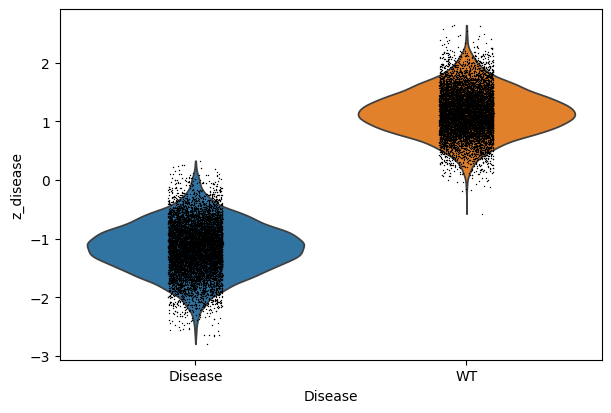

In [18]:
sc.pl.violin(adata,keys = 'z_disease', groupby='Disease')

In [19]:
adata.obsm['z_celltype_umap'] = UMAP().fit_transform(adata.obsm['z'][:,2:5])

/usr/local/lib/python3.8/dist-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


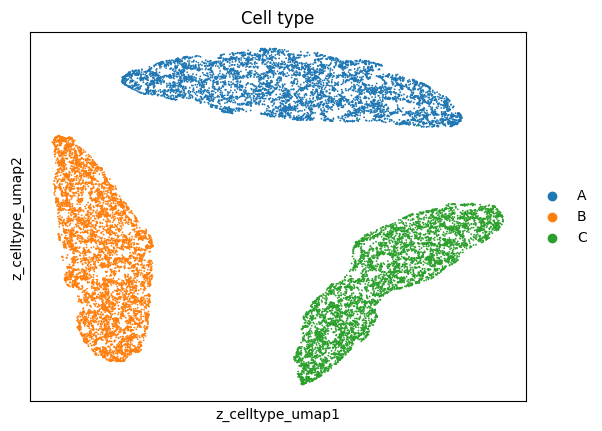

In [20]:
sc.pl.embedding(adata, basis = 'z_celltype_umap', color = 'Cell type')

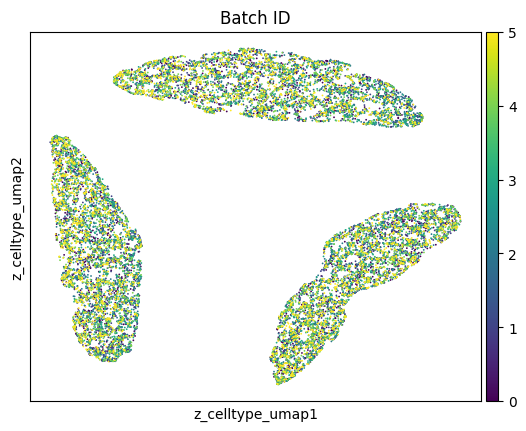

In [21]:
sc.pl.embedding(adata, basis = 'z_celltype_umap', color = 'Batch ID')

In [22]:
adata.obsm['z_batch_umap'] = UMAP().fit_transform(adata.obsm['z'][:,5:])

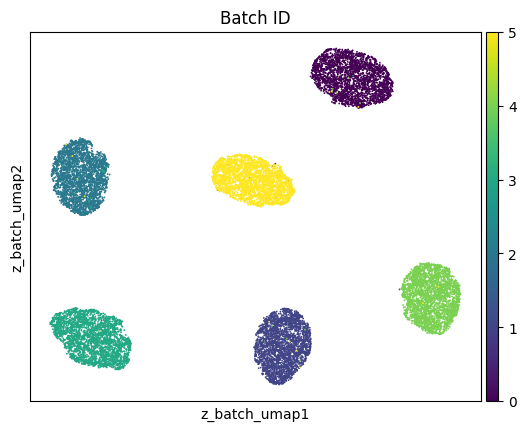

In [23]:
sc.pl.embedding(adata, basis = 'z_batch_umap', color = 'Batch ID')

/usr/local/lib/python3.8/dist-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


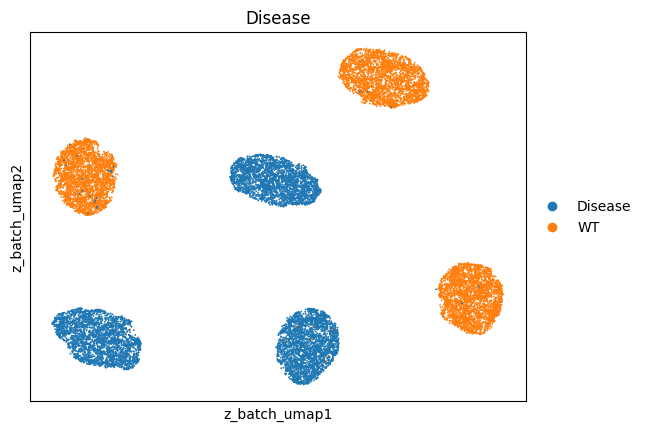

In [24]:
sc.pl.embedding(adata, basis = 'z_batch_umap', color = 'Disease')

In [26]:
z_corrected = knd.remove_batch(z, 
                               additional_removal=['scale'], #In addition to batches, variables whose values are to be replaced, specified by assignment metadata names. We recommend specifying "scale".
                               replace_values=[0,'median']) #Replacement values. Each value must be a number, "mean", or "median". The first value is for the batch variable, followed by values for the variables specified in additional_removal.
z_corrected

tensor([[ 9.4384,  1.6770, -1.2045,  ...,  0.0000,  0.0000,  0.0000],
        [ 9.4384,  1.0297,  0.1894,  ...,  0.0000,  0.0000,  0.0000],
        [ 9.4384,  0.9691, -0.0507,  ...,  0.0000,  0.0000,  0.0000],
        ...,
        [ 9.4384, -1.3391, -1.9049,  ...,  0.0000,  0.0000,  0.0000],
        [ 9.4384, -1.5060, -2.0682,  ...,  0.0000,  0.0000,  0.0000],
        [ 9.4384, -1.7613, -0.6857,  ...,  0.0000,  0.0000,  0.0000]])

In [27]:
mu_nb, theta, pi, scale = knd.decode(z_corrected) #decode the latent variables to ZINB parameters

/usr/local/lib/python3.8/dist-packages/kanade/kanade.py:295: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  z_tensor = torch.tensor(z, dtype=torch.float32)


In [28]:
counts = knd.resample(mu_nb, theta, pi, scale) #resampling from ZINB

/usr/local/lib/python3.8/dist-packages/torch/distributions/distribution.py:55: UserWarning: <class 'kanade.kanade_module.ZINB'> does not define `arg_constraints`. Please set `arg_constraints = {}` or initialize the distribution with `validate_args=False` to turn off validation.
  warnings.warn(


In [29]:
adata.raw = adata
adata.X = csr_matrix(counts)
adata.X

<18000x20000 sparse matrix of type '<class 'numpy.float32'>'
	with 16167884 stored elements in Compressed Sparse Row format>

In [30]:
adata.layers['reconst_counts'] = adata.X.copy()
sc.pp.log1p(adata)

In [31]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000)

In [32]:
sc.tl.pca(adata)

In [33]:
sc.pp.neighbors(adata)

In [34]:
sc.tl.umap(adata)

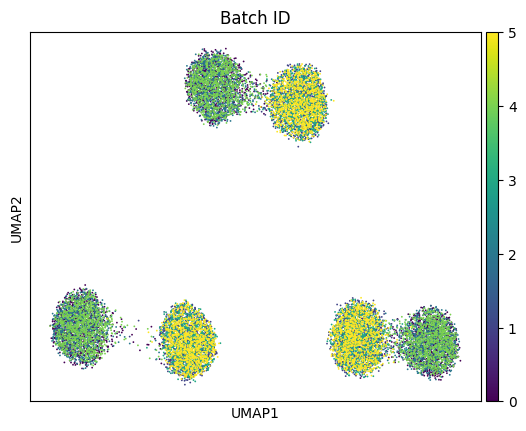

In [35]:
sc.pl.embedding(adata, basis = 'umap', color = 'Batch ID')

/usr/local/lib/python3.8/dist-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


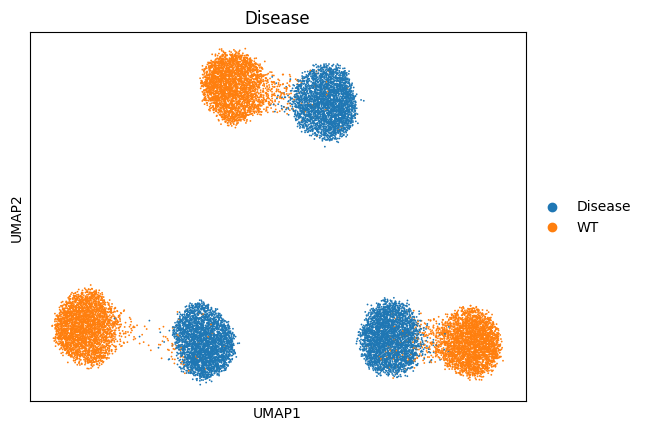

In [36]:
sc.pl.embedding(adata, basis = 'umap', color = 'Disease')

/usr/local/lib/python3.8/dist-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


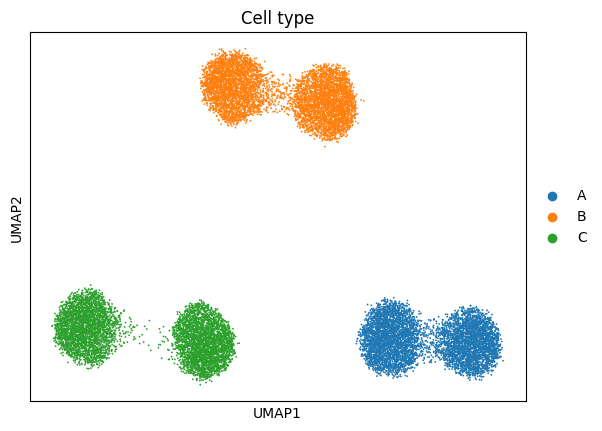

In [37]:
sc.pl.embedding(adata, basis = 'umap', color = 'Cell type')